<a href="https://colab.research.google.com/github/PiaokertheKTH/cb2330-portfolio/blob/main/group24_Global_quantification_of_mammalian_gene_expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
#import pandas as pd

In [2]:
### Random Variable
### We choose 'Pre-existing proteins' (Heavy protein) as random variable.
### Lt


In [3]:
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32


def lcg(state, a, c, m):
    """The next state of a linear congruential generator: s_{i+1} = (a * s_i + c) mod m."""
    return (a * state + c) % m


def uniforms(k, seed):
    """A list of k numbers on [0, 1): the generator run k times from the seed, each state divided by m."""
    out = [0.0] * k
    state = seed
    for i in range(k):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        out[i] = state / M_LCG
    return out

In [4]:
N = 10000   # number of L0
N_cell = 11  # number of cells

T_cell_dup = 27.5 #hour, given
T_half = 4.52 # hour, given
time_sep = 0.5 # per 30 minutes
K_dp = math.log(2) / T_half  # rate per hour
K_dil = math.log(2) / T_cell_dup
K_dp_dil = K_dp + K_dil
t_set = [1.5,4.5,13.5]
t_set_index = [int(time/time_sep)-1 for time in t_set]

# every proteins have equal chances to get into each cell.
protein_counts_in_cells = np.random.multinomial(N,[1/N_cell] * N_cell)
print(protein_counts_in_cells)
t_sample = np.arange(time_sep,t_set[-1]+time_sep,0.5)
H_counts = [0] * len(t_sample)
L_counts = [N] * len(t_sample)

p = 1 - math.exp(-K_dp_dil*time_sep)
print(p)
seed = 4242

rs = uniforms(N*len(t_sample),seed)

for i in range(N):
  for t_id in range(len(t_sample)):
    if rs[i*len(t_sample)+t_id] < p:
      H_counts[t_id:] = [x + 1 for x in H_counts[t_id:]]
      L_counts[t_id:] = [x - 1 for x in L_counts[t_id:]]
      break

print(t_sample)
print(H_counts)
print(L_counts)
print(t_set_index)
H_sample = [H_counts[i] for i in t_set_index]
L_sample = [L_counts[i] for i in t_set_index]
HL_ratio = np.array(H_sample) / np.array(L_sample)
ln_HL_ratio = np.log(1 + np.array(H_sample) / np.array(L_sample))
print(HL_ratio)
print(f'K_dp_dil:{K_dp_dil}, K_dil:{K_dil}')

[893 942 861 932 871 907 881 947 904 942 920]
0.08540894595407111
[ 0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5  7.
  7.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5]
[874, 1682, 2378, 3013, 3567, 4104, 4605, 5065, 5464, 5840, 6190, 6506, 6808, 7072, 7349, 7568, 7756, 7961, 8123, 8276, 8435, 8569, 8697, 8810, 8897, 9001, 9094]
[9126, 8318, 7622, 6987, 6433, 5896, 5395, 4935, 4536, 4160, 3810, 3494, 3192, 2928, 2651, 2432, 2244, 2039, 1877, 1724, 1565, 1431, 1303, 1190, 1103, 999, 906]
[2, 8, 26]
[ 0.3119916   1.20458554 10.03752759]
K_dp_dil:0.17855649816194247, K_dil:0.025205352020361647


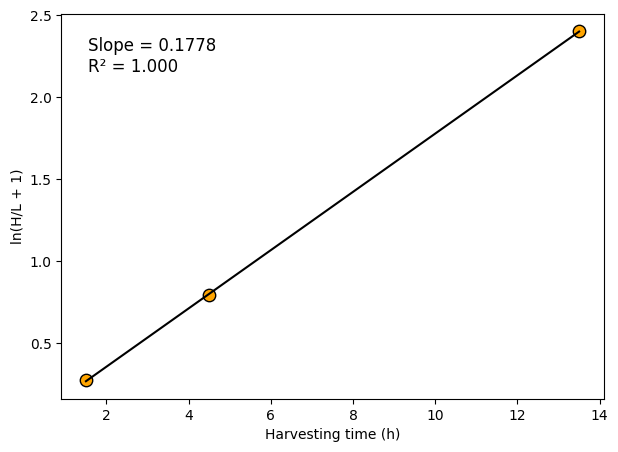

data_Kdp:0.1526189679242967,data_t_half:4.541684365889342
0.15335114614158082


In [5]:
# Your data
x = np.array(t_set)
y = np.array(ln_HL_ratio)

# Linear regression: y = slope * x + intercept
slope, intercept = np.polyfit(x, y, 1)

# Predicted values
y_pred = slope * x + intercept

# R-squared
r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - np.mean(y))**2)

# Draw
plt.figure(figsize=(7, 5))

plt.scatter(x, y, color="orange", edgecolor="black", s=80)
plt.plot(x, y_pred, color="black")

plt.xlabel("Harvesting time (h)")
plt.ylabel("ln(H/L + 1)")

plt.text(
    0.05, 0.85,
    f"Slope = {slope:.4f}\nR² = {r2:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12
)

plt.show()

data_Kdp = slope - K_dil
data_t_half = math.log(2) /data_Kdp
print(f'data_Kdp:{data_Kdp},data_t_half:{data_t_half}')
print(math.log(2)/4.52)

0.018019247557458318
[ 0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5  7.
  7.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5]
[199, 397, 564, 731, 893, 1047, 1205, 1370, 1507, 1629, 1777, 1931, 2063, 2227, 2407, 2518, 2630, 2771, 2877, 3009, 3156, 3278, 3397, 3506, 3617, 3744, 3859]
[9801, 9603, 9436, 9269, 9107, 8953, 8795, 8630, 8493, 8371, 8223, 8069, 7937, 7773, 7593, 7482, 7370, 7229, 7123, 6991, 6844, 6722, 6603, 6494, 6383, 6256, 6141]
[2, 8, 26]
[0.05977109 0.17744024 0.62839928]
K_dp_dil:0.03636714236754273, K_dil:0.025205352020361647


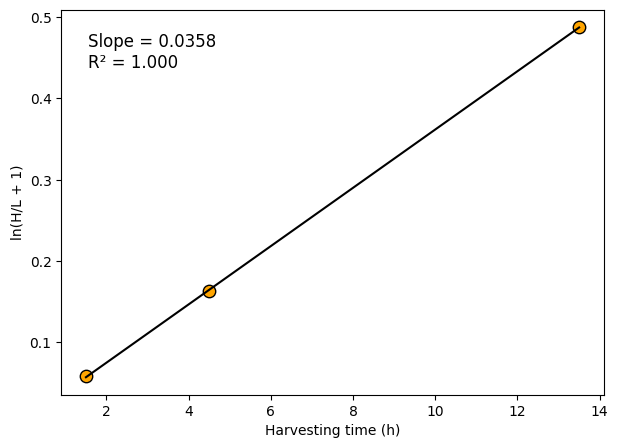

data_Kdp:0.010643779132100562,data_t_half:65.12228147138862
0.011161790347181084


In [6]:
N = 10000   # number of L0
N_cell = 100  # number of cells

T_cell_dup = 27.5 #hour, given
T_half = 62.1 # hour, given
time_sep = 0.5 # per 30 minutes
K_dp = math.log(2) / T_half  # rate per hour
K_dil = math.log(2) / T_cell_dup
K_dp_dil = K_dp + K_dil
t_set = [1.5,4.5,13.5]
t_set_index = [int(time/time_sep)-1 for time in t_set]

# every proteins have equal chances to get into each cell.
protein_counts_in_cells = np.random.multinomial(N,[1/N_cell] * N_cell)

t_sample = np.arange(time_sep,t_set[-1]+time_sep,0.5)
H_counts = [0] * len(t_sample)
L_counts = [N] * len(t_sample)

p = 1 - math.exp(-K_dp_dil*time_sep)
print(p)
seed = 4242

rs = uniforms(N*len(t_sample),seed)

for i in range(N):
  for t_id in range(len(t_sample)):
    if rs[i*len(t_sample)+t_id] < p:
      H_counts[t_id:] = [x + 1 for x in H_counts[t_id:]]
      L_counts[t_id:] = [x - 1 for x in L_counts[t_id:]]
      break

print(t_sample)
print(H_counts)
print(L_counts)
print(t_set_index)
H_sample = [H_counts[i] for i in t_set_index]
L_sample = [L_counts[i] for i in t_set_index]
HL_ratio = np.array(H_sample) / np.array(L_sample)
ln_HL_ratio = np.log(1 + np.array(H_sample) / np.array(L_sample))
print(HL_ratio)
print(f'K_dp_dil:{K_dp_dil}, K_dil:{K_dil}')

# Your data
x = np.array(t_set)
y = np.array(ln_HL_ratio)

# Linear regression: y = slope * x + intercept
slope, intercept = np.polyfit(x, y, 1)

# Predicted values
y_pred = slope * x + intercept

# R-squared
r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - np.mean(y))**2)

# Draw
plt.figure(figsize=(7, 5))

plt.scatter(x, y, color="orange", edgecolor="black", s=80)
plt.plot(x, y_pred, color="black")

plt.xlabel("Harvesting time (h)")
plt.ylabel("ln(H/L + 1)")

plt.text(
    0.05, 0.85,
    f"Slope = {slope:.4f}\nR² = {r2:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12
)

plt.show()

data_Kdp = slope - K_dil
data_t_half = math.log(2) /data_Kdp
print(f'data_Kdp:{data_Kdp},data_t_half:{data_t_half}')
print(math.log(2)/62.1)

[0.05606603 0.17780453 0.63387815]
K_dp_dil:0.03636714236754273, K_dil:0.025205352020361647


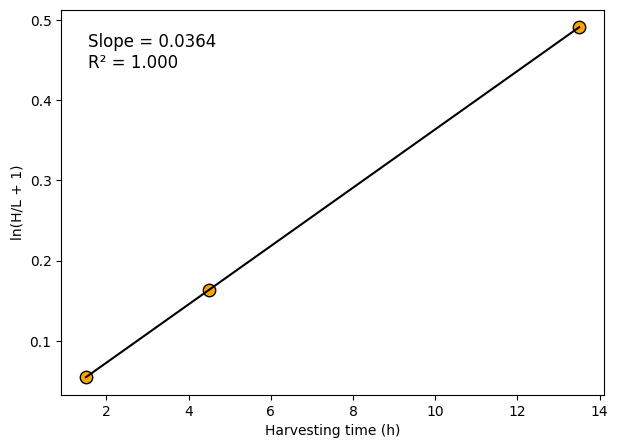

data_Kdp:0.011161790347181084,data_t_half:62.1
0.15335114614158082


In [7]:
def yield_model(N, t, k):
    """The fraction of material still full length after n cycles at a per-cycle efficiency p."""
    return N*math.exp(-t*k)

model_H_counts = [yield_model(N,i,K_dp_dil) for i in t_sample]
model_L_counts = [N-yield_model(N,i,K_dp_dil) for i in t_sample]

H_sample = [model_L_counts[i] for i in t_set_index]
L_sample = [model_H_counts[i] for i in t_set_index]
HL_ratio = np.array(H_sample) / np.array(L_sample)
ln_HL_ratio = np.log(1 + np.array(H_sample) / np.array(L_sample))
print(HL_ratio)
print(f'K_dp_dil:{K_dp_dil}, K_dil:{K_dil}')

# Your data
x = np.array(t_set)
y = np.array(ln_HL_ratio)

# Linear regression: y = slope * x + intercept
slope, intercept = np.polyfit(x, y, 1)

# Predicted values
y_pred = slope * x + intercept

# R-squared
r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - np.mean(y))**2)

# Draw
plt.figure(figsize=(7, 5))

plt.scatter(x, y, color="orange", edgecolor="black", s=80)
plt.plot(x, y_pred, color="black")

plt.xlabel("Harvesting time (h)")
plt.ylabel("ln(H/L + 1)")

plt.text(
    0.05, 0.85,
    f"Slope = {slope:.4f}\nR² = {r2:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12
)

plt.show()

data_Kdp = slope - K_dil
data_t_half = math.log(2) /data_Kdp
print(f'data_Kdp:{data_Kdp},data_t_half:{data_t_half}')
print(math.log(2)/4.52)




In [8]:
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32


def lcg(state, a, c, m):
    """The next state of a linear congruential generator: s_{i+1} = (a * s_i + c) mod m."""
    return (a * state + c) % m


def uniforms(k, seed):
    """A list of k numbers on [0, 1): the generator run k times from the seed, each state divided by m."""
    out = [0.0] * k
    state = seed
    for i in range(k):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        out[i] = state / M_LCG
    return out

p:0.07380971405997816
cell_ages:[ 8.22668142 25.59129264 18.07955495 ... 25.44009708  8.79078291
  4.55968997]
total_counts[101134, 102361, 103780, 105012, 106471, 107740, 108992, 110249, 111454, 112940, 114373, 115616, 117039, 118685, 120304, 121644, 123026, 124447, 125967, 127573, 129015, 130702, 132574, 134335, 136079, 137754, 139510]
H_counts:[8713, 16618, 24464, 31531, 38509, 44742, 50643, 56136, 61353, 66562, 71477, 75847, 80243, 84531, 88703, 92421, 95956, 99462, 102838, 106148, 109212, 112387, 115591, 118636, 121562, 124370, 127098]
HL_ratio:[ 0.30843714  1.22458634 10.2399291 ]


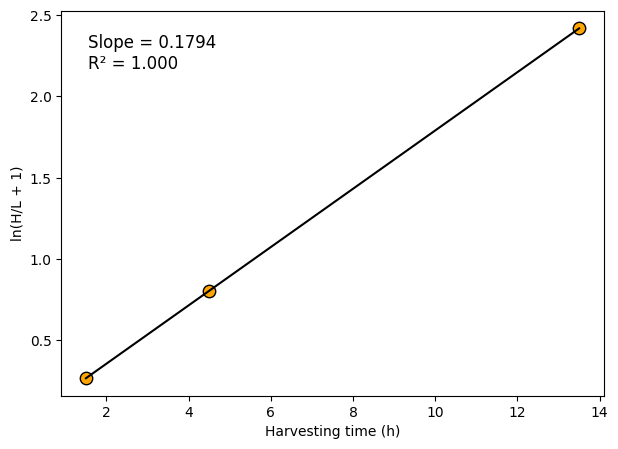

data_Kdp:0.15419206839427332, data_t_half:4.495349130329772


In [9]:
#Considering cell division
import math
import matplotlib.pyplot as plt
import numpy as np
# experimantal parameters
T_cell_dup = 27.5 #hour, given
T_half = 4.52 # hour, given


# self-defined parameters
N = 100000   # number of L0
N_cell = 10000  # number of cells
time_sep = 0.5 # simulate per 30 minutes
seed = 42

# set seed
np.random.seed(seed)

# Sampled time points
t_set = [1.5,4.5,13.5]
t_sample = np.arange(time_sep,t_set[-1]+time_sep,0.5)
t_set_index = [int(time/time_sep)-1 for time in t_set]


# Deduced protein dilimination rate
K_dp = math.log(2) / T_half  # rate per hour


# protein degradation probability
p = 1 - math.exp(-K_dp*time_sep)
print(f'p:{p}')


# original cell ages
cell_growth_rate = np.log(2) / T_cell_dup

u = np.random.random(N_cell)
cell_ages = -np.log(1 - u / 2) / cell_growth_rate
print(f'cell_ages:{cell_ages}')


# original Light proteins number in each cell
protein_counts_in_cells = np.random.multinomial(N,[1/N_cell] * N_cell)


# calcualate total protein counts for every time points
total_counts = [0] * len(t_sample)


for i in range(len(t_sample)):
  total_counts[i] += int(sum([protein_counts_in_cells[j]*2**((cell_ages[j] + t_sample[i]) // T_cell_dup) for j in range(N_cell)]))

print(f'total_counts{total_counts}')
L_counts = [N] * len(t_sample)


# generate cell divide matrix
if_divide_matrix = np.zeros((len(t_sample),N_cell))


# Simulation without formula
state = seed
state = lcg(state, A_LCG, C_LCG, M_LCG)
L_rs = uniforms(N * len(t_sample), state)


for i in range(N):
  for t_id in range(len(t_sample)):
    if L_rs[i*len(t_sample)+t_id] < p:
      # H_counts[t_id:] = [x + 1 for x in H_counts[t_id:]]
      L_counts[t_id:] = [x - 1 for x in L_counts[t_id:]]
      break

H_counts = [total_counts[i] - L_counts[i] for i in range(len(t_sample))]
print(f'H_counts:{H_counts}')

H_sample = [H_counts[i] for i in t_set_index]
L_sample = [L_counts[i] for i in t_set_index]
HL_ratio = np.array(H_sample) / np.array(L_sample)
print(f'HL_ratio:{HL_ratio}')
ln_HL_ratio = np.log(1 + np.array(H_sample) / np.array(L_sample))




#### DRAW
# Your data
x = np.array(t_set)
y = np.array(ln_HL_ratio)

# Linear regression: y = slope * x + intercept
slope, intercept = np.polyfit(x, y, 1)

# Predicted values
y_pred = slope * x + intercept

# R-squared
r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - np.mean(y))**2)

# Draw
plt.figure(figsize=(7, 5))

plt.scatter(x, y, color="orange", edgecolor="black", s=80)
plt.plot(x, y_pred, color="black")

plt.xlabel("Harvesting time (h)")
plt.ylabel("ln(H/L + 1)")

plt.text(
    0.05, 0.85,
    f"Slope = {slope:.4f}\nR² = {r2:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12
)

plt.show()


data_Kdp = slope - math.log(2) / T_cell_dup
data_t_half = math.log(2) / data_Kdp
print(f'data_Kdp:{data_Kdp}, data_t_half:{data_t_half}')


In [10]:
## backward parameter estimation




